<a href="https://colab.research.google.com/github/HeyWinTomsy/MN/blob/main/%D0%9B%D0%B0%D0%B111_%D0%90%D0%BD%D1%82%D1%80%D0%BE%D0%BF%D0%BE%D0%B2_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install -q kaggle tensorflow pandas numpy matplotlib scikit-learn pillow
!pip install -q kagglehub

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import kagglehub

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

print("Датасет завантажено:", path)

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Датасет завантажено: /kaggle/input/gtsrb-german-traffic-sign


In [10]:
for root, dirs, files_list in os.walk(path):
    print(root, files_list[:5])

    if root.count(os.sep) > 3:
        dirs.clear()

/kaggle/input/gtsrb-german-traffic-sign ['Meta.csv', 'Train.csv', 'Test.csv']
/kaggle/input/gtsrb-german-traffic-sign/Meta ['37.png', '35.png', '11.png', '31.png', '4.png']
/kaggle/input/gtsrb-german-traffic-sign/meta ['37.png', '35.png', '11.png', '31.png', '4.png']
/kaggle/input/gtsrb-german-traffic-sign/Test ['01301.png', '02578.png', '06781.png', '11396.png', '00929.png']
/kaggle/input/gtsrb-german-traffic-sign/test ['01301.png', '02578.png', '06781.png', '11396.png', '00929.png']
/kaggle/input/gtsrb-german-traffic-sign/Train []
/kaggle/input/gtsrb-german-traffic-sign/train []


In [14]:
DATA_DIR = Path(path)

train_csv = next(DATA_DIR.rglob('Train.csv'))
test_csv = next(DATA_DIR.rglob('Test.csv'))

train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

print("Навчальний набір:")
display(train_df.head())

print("Тестовий набір:")
display(test_df.head())

print("Навчальних зображень:", len(train_df))
print("Тестових зображень:", len(test_df))

Навчальний набір:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


Тестовий набір:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


Навчальних зображень: 39209
Тестових зображень: 12630


In [15]:
IMG_SIZE = 48
NUM_CLASSES = 43

def load_images(df, csv_path):
    images = []
    labels = []

    base_dir = csv_path.parent

    for _, row in df.iterrows():
        img_path = base_dir / str(row['Path'])

        img = Image.open(img_path).convert('RGB')
        img = img.resize((IMG_SIZE, IMG_SIZE))

        images.append(np.array(img))
        labels.append(int(row['ClassId']))

    return np.array(images), np.array(labels)


X, y = load_images(train_df, train_csv)
X_test, y_test = load_images(test_df, test_csv)

X = X.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Навчальні зображення:", X.shape)
print("Тестові зображення:", X_test.shape)

Навчальні зображення: (39209, 48, 48, 3)
Тестові зображення: (12630, 48, 48, 3)


In [16]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Перевірочна вибірка:", X_val.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (31367, 48, 48, 3)
Перевірочна вибірка: (7842, 48, 48, 3)
Тестова вибірка: (12630, 48, 48, 3)


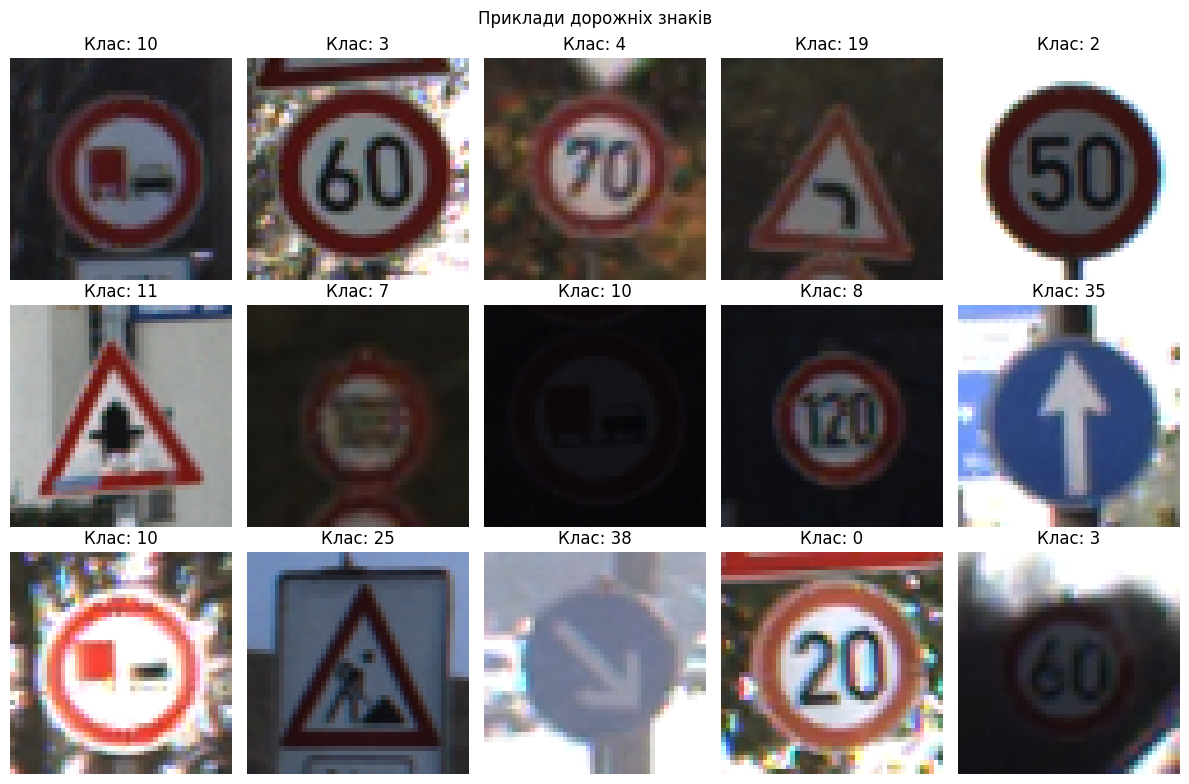

In [17]:
plt.figure(figsize=(12, 8))

indices = np.random.choice(
    len(X_train), 15, replace=False
)

for i, idx in enumerate(indices):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_train[idx])
    plt.title(f"Клас: {y_train[idx]}")
    plt.axis('off')

plt.suptitle("Приклади дорожніх знаків")
plt.tight_layout()
plt.show()

In [18]:
model = models.Sequential([
    layers.Input(shape=(48, 48, 3)),

    # Аугментація зображень
    layers.RandomRotation(0.08),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomZoom(0.1),

    # Перший згортковий блок
    layers.Conv2D(32, (3, 3), padding='same',
                  activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Другий згортковий блок
    layers.Conv2D(64, (3, 3), padding='same',
                  activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Третій згортковий блок
    layers.Conv2D(128, (3, 3), padding='same',
                  activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Класифікатор
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),

    # 43 класи дорожніх знаків
    layers.Dense(43, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 48, 48, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 48, 48, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 116,203 (453.92 KB)

 Trainable params: 115,755 (452.17 KB)

 Non-trainable params: 448 (1.75 KB)

In [19]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [20]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

In [22]:
history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9478 - loss: 0.1779 - val_accuracy: 0.9881 - val_loss: 0.0463 - learning_rate: 0.0010
Epoch 2/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9542 - loss: 0.1580 - val_accuracy: 0.9883 - val_loss: 0.0492 - learning_rate: 0.0010
Epoch 3/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9625 - loss: 0.1251 - val_accuracy: 0.9704 - val_loss: 0.1092 - learning_rate: 0.0010
Epoch 4/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9750 - loss: 0.0859 - val_accuracy: 0.9962 - val_loss: 0.0146 - learning_rate: 5.0000e-04
Epoch 5/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9778 - loss: 0.0745 - val_accuracy: 0.9964 - val_loss: 0.0137 - learning_rate: 5.0000e-04
Epoch 6/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9761 - loss: 0.0782 - val_accuracy: 0.9912 - val_loss: 0.0320 - learning_rate: 5.0000e-04
Epoch 7/25
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.97

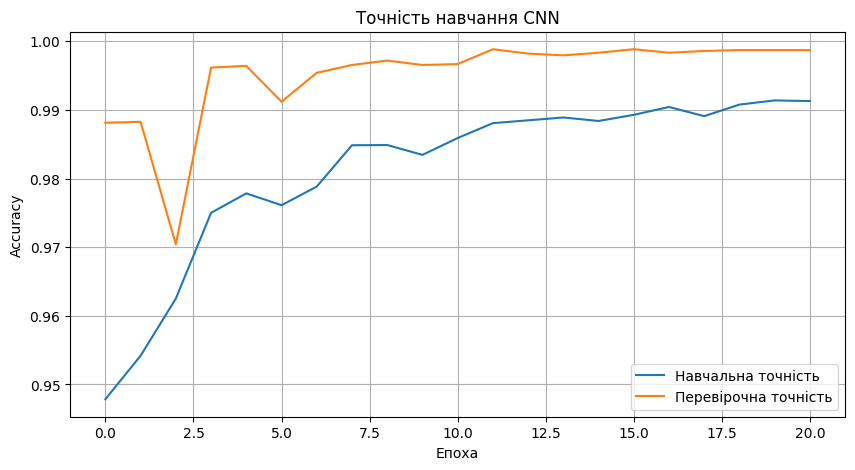

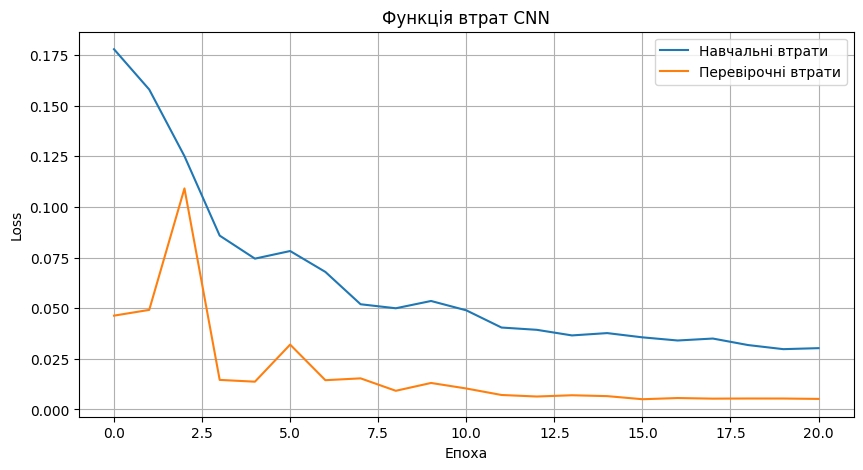

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'],
         label='Навчальна точність')

plt.plot(history.history['val_accuracy'],
         label='Перевірочна точність')

plt.title('Точність навчання CNN')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'],
         label='Навчальні втрати')

plt.plot(history.history['val_loss'],
         label='Перевірочні втрати')

plt.title('Функція втрат CNN')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9760 - loss: 0.0877
Test Loss: 0.0877
Test Accuracy: 97.60%


In [25]:
predictions = model.predict(X_test)

y_pred = np.argmax(predictions, axis=1)

print("Справжні класи:", y_test[:15])
print("Прогнозовані класи:", y_pred[:15])

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Справжні класи: [16  1 38 33 11 38 18 12 25 35 12  7 23  7  4]
Прогнозовані класи: [16  1 38 33 11 38 18 12 25 35 12  7 23  7  4]


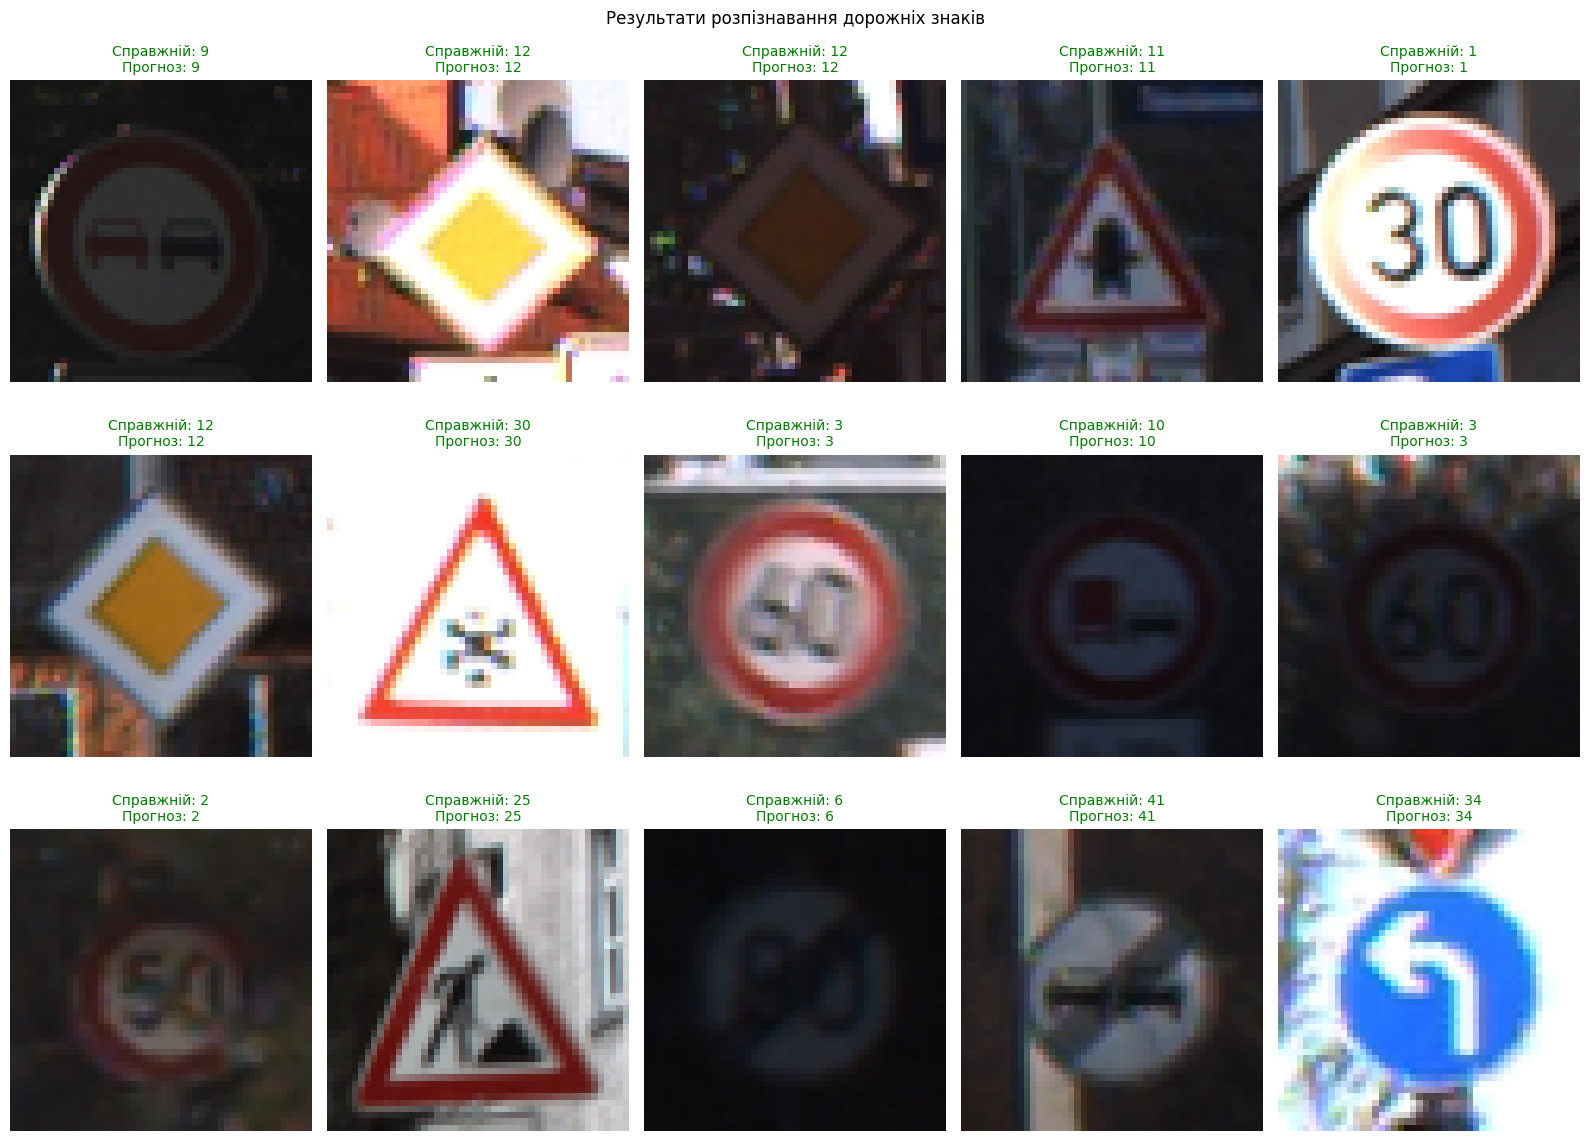

In [26]:
plt.figure(figsize=(16, 12))

indices = np.random.choice(
    len(X_test), 15, replace=False
)

for i, idx in enumerate(indices):
    true_class = y_test[idx]
    predicted_class = y_pred[idx]

    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[idx])

    color = 'green' if true_class == predicted_class else 'red'

    plt.title(
        f"Справжній: {true_class}\n"
        f"Прогноз: {predicted_class}",
        color=color,
        fontsize=10
    )

    plt.axis('off')

plt.suptitle("Результати розпізнавання дорожніх знаків")
plt.tight_layout()
plt.show()

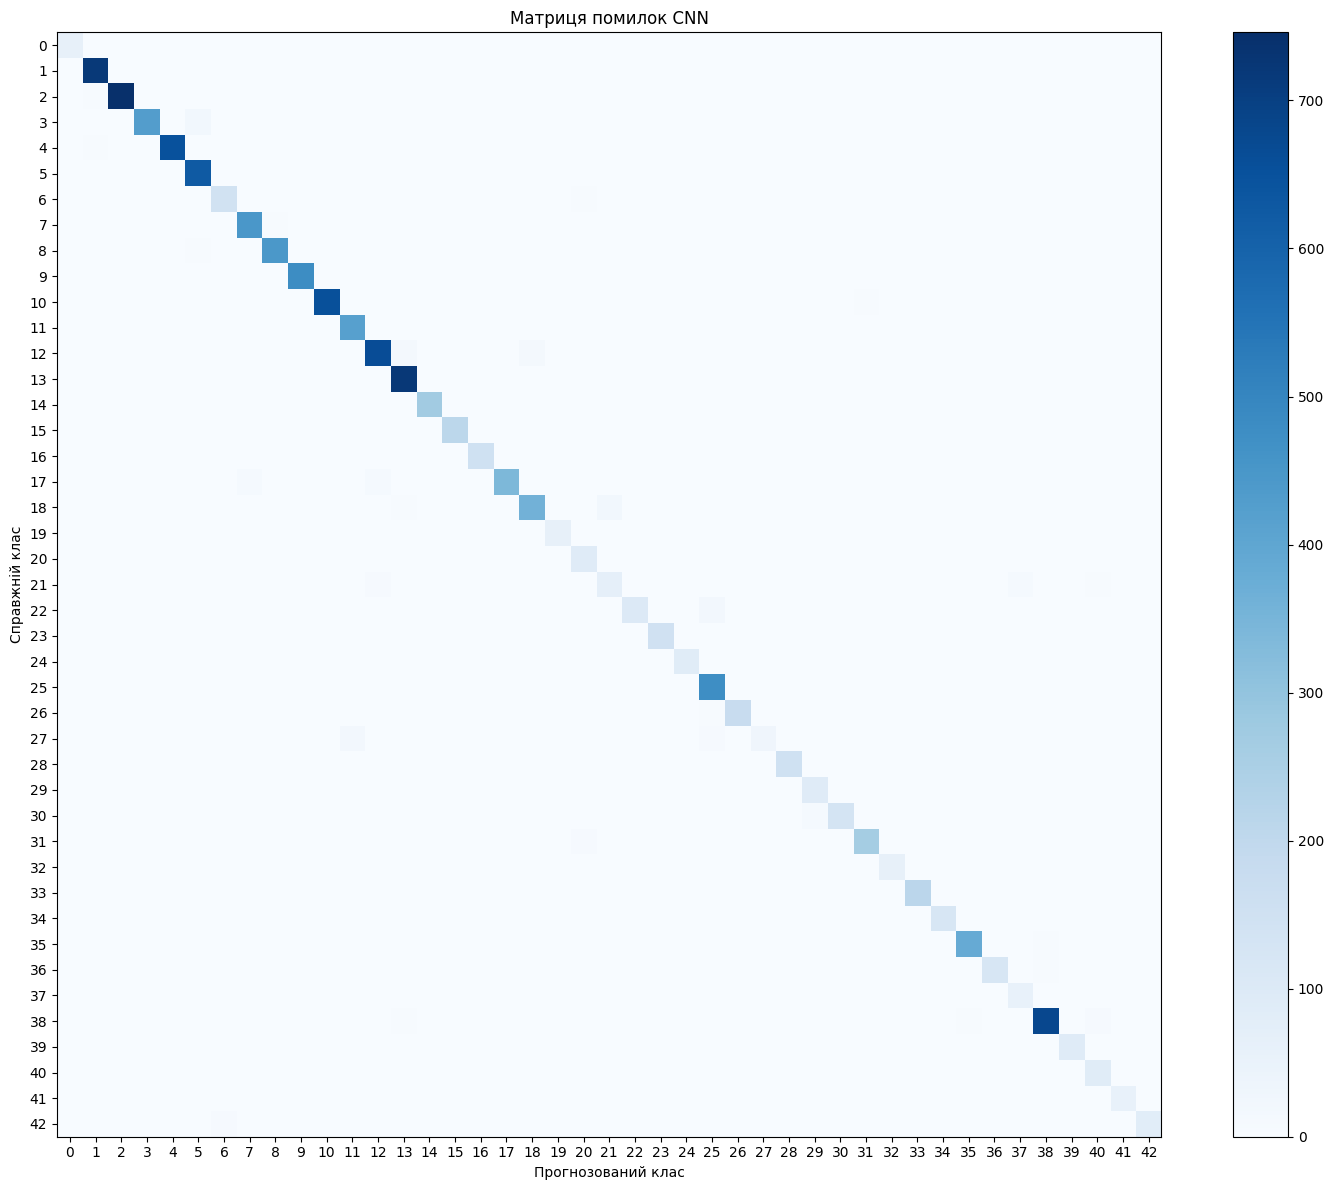

In [27]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(15, 12))
plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.title("Матриця помилок CNN")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")

plt.xticks(range(43))
plt.yticks(range(43))

plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99        60
           1       0.99      1.00      0.99       720
           2       0.99      0.99      0.99       750
           3       1.00      0.95      0.97       450
           4       1.00      0.98      0.99       660
           5       0.96      0.99      0.98       630
           6       0.95      0.95      0.95       150
           7       0.98      0.99      0.99       450
           8       0.99      0.99      0.99       450
           9       0.99      1.00      1.00       480
          10       1.00      0.99      1.00       660
          11       0.95      1.00      0.97       420
          12       0.97      0.96      0.97       690
          13       0.97      1.00      0.99       720
          14       1.00      1.00      1.00       270
          15       1.00      0.99      1.00       210
          16       0.99      1.00      1.00       150
          17       1.00    

Висновок:

У ході лаабораторної роботи, я розробив та навчив згорткову нейронну мережу для розпізнавання дорожніх знаків на наборі данних GTSRB, який містить 43 класи.

Спершу я провів попередню обробку зображень, нармалізуввав данні та розподілив їх на навчальну, перевірочну й тесстові ввибірки. Далі я побудував CNN із трьома згортковвими блокаам, шарами BatchNormalization? MaxPooling та Dropout.

Модель досягнула перевірочної точності 99.89%. Після її тестування, я отримав точність 97.60%, та значення функції втрат 0ю0877.

Ще я побудував граафіки навчаання та виконав оцінювання здатності моделі розпізнавати дорожні знаки.

Моя згорткова нейронна мережа продемонструвалла високу ефективність у класифікацції зображеннь дорожніх знаків.